In [2]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/elifsudayi/food-recipe-finder.git
%cd food-recipe-finder
!pip install -q -r requirements.txt

!tar -xf /content/drive/MyDrive/swe015/food10.tar -C /content
!ls /content/food10
!mkdir -p models results

Mounted at /content/drive
Cloning into 'food-recipe-finder'...
remote: Enumerating objects: 93, done.
remote: Counting objects: 100% (93/93), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 93 (delta 34), reused 76 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (93/93), 491.04 KiB | 10.67 MiB/s, done.
Resolving deltas: 100% (34/34), done.
/content/food-recipe-finder
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
test  train  val


In [3]:
import sys, json; sys.path.append(".")
import torch
from src.config import SEED
from src.utils import set_seed, get_device, hardware_info, count_params
from src.image.data import get_loaders
from src.image.models import SmallCNN
from src.image.train import fit, evaluate

set_seed(SEED)
device = get_device()
print(device, hardware_info())

IMG = 128
loaders, class_names = get_loaders("/content/food10", img_size=IMG, batch_size=64)
print(class_names)
print({k: len(v.dataset) for k, v in loaders.items()})

model = SmallCNN(num_classes=len(class_names), dropout=0.5)
print("number of parameters:", count_params(model))

cuda {'cpu': 'Intel(R) Xeon(R) CPU @ 2.00GHz', 'cpu_count': 2, 'gpu': 'Tesla T4', 'torch': '2.14.1+cu130'}
['caesar_salad', 'chicken_curry', 'french_fries', 'hamburger', 'ice_cream', 'omelette', 'pancakes', 'pizza', 'spaghetti_carbonara', 'sushi']
{'train': 6500, 'val': 1000}
number of parameters: 391466


In [4]:
history_test, _ = fit(model, loaders, device, epochs=1, lr=0.05,
                      weight_decay=5e-4, ckpt_path="models/tmp.pt", label="[trial] ")

[trial] ep 01/1 | train loss 2.243 acc 0.221 | val loss 2.082 top1 0.249 top5 0.733 | 36s


In [5]:
set_seed(SEED)
model = SmallCNN(num_classes=len(class_names), dropout=0.5)
history, best_val = fit(model, loaders, device, epochs=30, lr=0.05,
                        weight_decay=5e-4, ckpt_path="models/small_cnn.pt")
print("best val top-1:", best_val)

ep 01/30 | train loss 2.243 acc 0.221 | val loss 2.082 top1 0.249 top5 0.733 | 32s
ep 02/30 | train loss 2.056 acc 0.259 | val loss 1.944 top1 0.304 top5 0.813 | 31s
ep 03/30 | train loss 1.953 acc 0.313 | val loss 1.913 top1 0.347 top5 0.803 | 31s
ep 04/30 | train loss 1.911 acc 0.323 | val loss 1.903 top1 0.352 top5 0.810 | 31s
ep 05/30 | train loss 1.799 acc 0.370 | val loss 1.794 top1 0.391 top5 0.830 | 32s
ep 06/30 | train loss 1.698 acc 0.411 | val loss 1.728 top1 0.411 top5 0.853 | 31s
ep 07/30 | train loss 1.617 acc 0.454 | val loss 1.513 top1 0.490 top5 0.898 | 31s
ep 08/30 | train loss 1.542 acc 0.482 | val loss 1.448 top1 0.510 top5 0.907 | 31s
ep 09/30 | train loss 1.479 acc 0.498 | val loss 1.712 top1 0.451 top5 0.879 | 31s
ep 10/30 | train loss 1.418 acc 0.524 | val loss 1.347 top1 0.551 top5 0.924 | 30s
ep 11/30 | train loss 1.368 acc 0.543 | val loss 1.467 top1 0.521 top5 0.888 | 30s
ep 12/30 | train loss 1.302 acc 0.561 | val loss 1.294 top1 0.571 top5 0.932 | 31s
ep 1

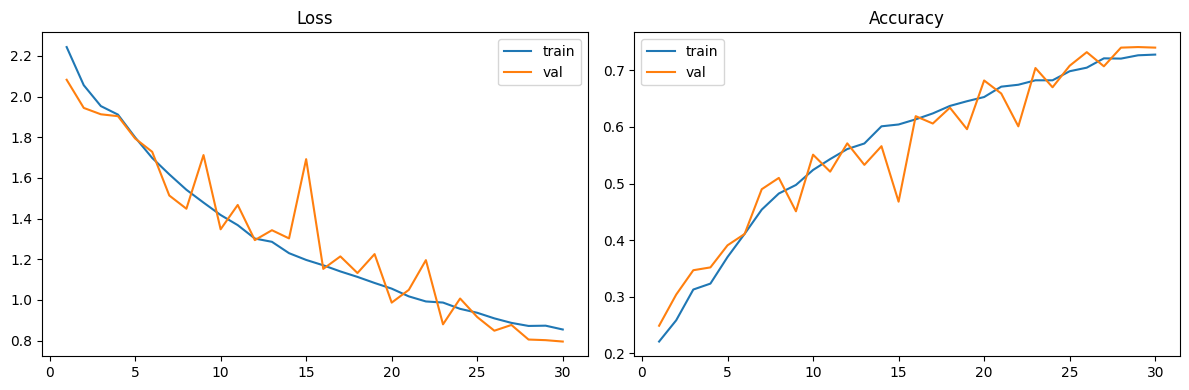

In [6]:
import matplotlib.pyplot as plt
ep = [h["epoch"] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, [h["train_loss"] for h in history], label="train")
ax[0].plot(ep, [h["val_loss"] for h in history], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(ep, [h["train_acc"] for h in history], label="train")
ax[1].plot(ep, [h["val_top1"] for h in history], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig("results/small_cnn_curves.png", dpi=150); plt.show()

In [7]:
from src.image.data import get_loaders
from src.utils import model_size_mb, latency_ms

best = SmallCNN(num_classes=len(class_names))
best.load_state_dict(torch.load("models/small_cnn.pt", map_location="cpu"))

test_loader = get_loaders("/content/food10", IMG, splits=("test",))[0]["test"]
res = evaluate(best.to(device), test_loader, device)
lat = latency_ms(best, input_shape=(1, 3, IMG, IMG), runs=100, device="cpu")

metrics = {"model": "small_cnn_fp32", "test_top1": res["top1"], "test_top5": res["top5"],
           "size_mb": model_size_mb(best), "latency_cpu_ms": lat,
           "params": count_params(best), "class_names": class_names,
           "hardware": hardware_info()}
json.dump(metrics, open("results/small_cnn_metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))

{
  "model": "small_cnn_fp32",
  "test_top1": 0.802,
  "test_top5": 0.9812,
  "size_mb": 1.578261,
  "latency_cpu_ms": {
    "mean_ms": 14.277155509996646,
    "std_ms": 2.835918021721168,
    "runs": 100
  },
  "params": 391466,
  "class_names": [
    "caesar_salad",
    "chicken_curry",
    "french_fries",
    "hamburger",
    "ice_cream",
    "omelette",
    "pancakes",
    "pizza",
    "spaghetti_carbonara",
    "sushi"
  ],
  "hardware": {
    "cpu": "Intel(R) Xeon(R) CPU @ 2.00GHz",
    "cpu_count": 2,
    "gpu": "Tesla T4",
    "torch": "2.14.1+cu130"
  }
}


In [8]:
!cp models/small_cnn.pt /content/drive/MyDrive/swe015/
!cp results/small_cnn_metrics.json results/small_cnn_curves.png /content/drive/MyDrive/swe015/